# Demo of WGD on the EOT functional

We use the noisy-circle deconvolution example from [wgd_demo.ipynb](wgd_demo.ipynb) to compare
WGD on the EOT and BA functionals, using the same source samples, initial particles, weights, and learning rate.

### Set up the experiment

In [1]:
from pathlib import Path
import base64
import sys
import time

# Add the project root to the import path.
project_dir = Path.cwd().resolve()
if not (project_dir / 'eotgd').is_dir():
  project_dir = project_dir.parent
if not (project_dir / 'eotgd').is_dir():
  raise RuntimeError('Start this notebook from the wgd repository or its notebooks/ directory.')
if str(project_dir) not in sys.path:
  sys.path.insert(0, str(project_dir))

import jax
jax.config.update('jax_enable_x64', True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML, Markdown, display
from scipy.optimize import brentq, linear_sum_assignment

from bagd.core import wgrad_baf, estimate_rd
from eotgd.main import wgrad_eot, estimate_eot, validate_inputs

plt.rcParams.update({'figure.dpi': 100, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'text.usetex': False, 'mathtext.fontset': 'cm'})
colors = {'BA': '#0072B2', 'EOT': '#D55E00'}
method_labels = {'BA': r'WGD on $F_{\mathrm{BA}}$', 'EOT': r'WGD on $F_{\mathrm{EOT}}$'}
print('JAX', jax.__version__, '| devices:', jax.devices())

JAX 0.10.2 | devices: [CpuDevice(id=0)]


### BA and EOT functionals

Let $\mu$ be the source distribution of the data $x$, and let $\nu$ be the reproduction distribution
that we want to optimize. For the deconvolution example, both are on $\mathbb R^2$, with distortion
$\rho(x,y)=\tfrac12\|x-y\|^2$. The parameter $\lambda>0$ controls the rate-distortion tradeoff.

Consider optimizing the BA and EOT functionals from [Eqs. (5)–(7) of the paper](https://arxiv.org/pdf/2310.18908),
with $\epsilon=1/\lambda$. To compare them at the same scale, write
$F_{\mathrm{BA}}(\nu)=L_{\mathrm{BA}}(\mu,\nu)$ and $F_{\mathrm{EOT}}(\nu)=\lambda L_{\mathrm{EOT}}(\mu,\nu)$:

$$
\begin{aligned}
F_{\mathrm{BA}}(\nu)
&=\inf_{\pi\in\Pi(\mu,\cdot)}
\left\{\lambda\int\rho(x,y)\,\pi(dx,dy)+H(\pi\mid\mu\otimes\nu)\right\},\\
F_{\mathrm{EOT}}(\nu)
&=\inf_{\pi\in\Pi(\mu,\nu)}
\left\{\lambda\int\rho(x,y)\,\pi(dx,dy)+H(\pi\mid\mu\otimes\nu)\right\}.
\end{aligned}
$$

Here $\pi$ is a joint distribution over $(x,y)$, and $H$ denotes relative entropy (KL divergence).
$\Pi(\mu,\cdot)$ fixes only the first marginal to $\mu$, while $\Pi(\mu,\nu)$ also fixes the
second marginal to $\nu$. The two functionals have the same global minimizers over
$\mathcal P(\mathbb R^2)$ (Eq. (9)); their finite-particle solutions can differ.

### Discrete computation

We approximate $\mu$ using $m$ source samples and represent $\nu$ by $n$ particles:

$$
\mu_m=\sum_{i=1}^m a_i\delta_{x_i},\qquad
\nu=\sum_{j=1}^n b_j\delta_{y_j}.
$$

The probability vectors $a\in\mathbb R^m$ and $b\in\mathbb R^n$ give the source and particle weights,
respectively. They are non-negative and sum to one. In this demo $a_i=1/m$ and $b_j=1/n$;
WGD moves the particles $y_j$ while keeping $b$ fixed.
The arrays `mu_x` and `nu_x` store the locations, and `mu_w` and `nu_w` store $a$ and $b$
as a column and row vector of shapes `(m, 1)` and `(1, n)`.

At a given step, let $C_{ij}=\rho(x_i,y_j)$ be the $m\times n$ distortion matrix and
$P\in\mathbb R_+^{m\times n}$ the joint probability matrix. Its row and column sums are the
source and reproduction marginals. With $\langle C,P\rangle=\sum_{ij}C_{ij}P_{ij}$ and
$\mathrm{KL}(P\Vert ab^\top)=\sum_{ij}P_{ij}\log(P_{ij}/(a_i b_j))$, the discrete objectives are

$$
\begin{aligned}
F_{\mathrm{BA}}(\nu)
&=\min_{\substack{P\ge0\\P\mathbf 1_n=a}}
\left\{\lambda\langle C,P\rangle+\mathrm{KL}(P\Vert ab^\top)\right\},\\
F_{\mathrm{EOT}}(\nu)
&=\min_{\substack{P\ge0\\P\mathbf 1_n=a,\;P^\top\mathbf 1_m=b}}
\left\{\lambda\langle C,P\rangle+\mathrm{KL}(P\Vert ab^\top)\right\}.
\end{aligned}
$$

The BA inner problem has the closed form

$$
F_{\mathrm{BA}}(\nu)=-\sum_{i=1}^m a_i\log\left(\sum_{j=1}^n b_j e^{-\lambda C_{ij}}\right),
$$

whereas EOT requires Sinkhorn iterations. Both implementations use `rd_lambda` for $\lambda$
and return the scaled objectives above as `loss`.

### Noisy-circle deconvolution

We generate $X=Y+Z$, where $Y\sim\nu^*$ is uniform on the unit circle and
$Z\sim\mathcal N(0,\sigma^2 I_2)$ is independent noise with $\sigma^2=0.1$.
The noisy source distribution is $\mu$, and $\mu_m$ is its empirical approximation.
With `half_sse` and $\lambda=1/\sigma^2=10$, the latent circle $\nu^*$ is the optimal
reproduction distribution for the population problem (Sec. 2.3 of the paper).
The plots show samples $x\sim\mu$, the circle $\nu^*$, and the evolving particles of $\nu^{(t)}$.

In [2]:
seed = 0
m, n = 2048, 7
num_steps = 600
record_every = 10
noise_var = 0.1
rd_lambda = 1 / noise_var
learning_rate = 0.02
sink_tol = 1e-9
max_sink_its = 2000
distort_type = 'half_sse'

rng = np.random.default_rng(seed)
angles = rng.uniform(0, 2 * np.pi, size=m)
clean_x = np.stack([np.cos(angles), np.sin(angles)], axis=1)
train_X = clean_x + np.sqrt(noise_var) * rng.normal(size=(m, 2))
mu_x = jnp.asarray(train_X)
mu_w = jnp.ones((m, 1)) / m
nu_w = jnp.ones((1, n)) / n
nu_x_init = jnp.asarray(train_X[rng.choice(m, n, replace=False)].copy())
validate_inputs(mu_x, mu_w, nu_x_init, nu_w, rd_lambda)

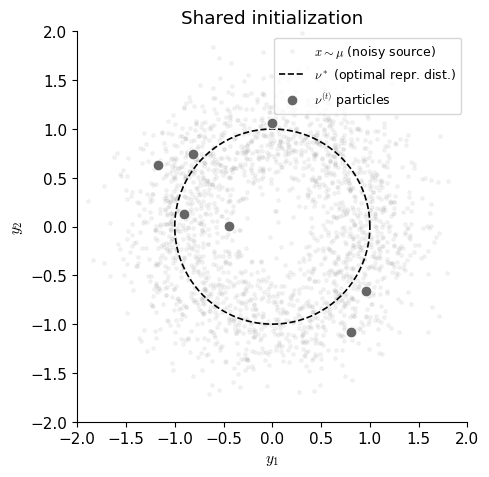

In [3]:
def make_scatter(ax, points, title, color, trajectories=None):
  ax.scatter(train_X[:, 0], train_X[:, 1], s=6, alpha=0.08,
             color='gray', rasterized=True, label=r'$x \sim \mu$ (noisy source)')
  theta = np.linspace(0, 2*np.pi, 200)
  ax.plot(np.cos(theta), np.sin(theta), '--', color='black', lw=1.2,
          label=r'$\nu^*$ (optimal repr. dist.)')
  if trajectories is not None:
    for j in range(trajectories.shape[1]):
      ax.plot(trajectories[:, j, 0], trajectories[:, j, 1], color=color, alpha=0.45, lw=1)
  ax.scatter(points[:, 0], points[:, 1], s=60, color=color,
             edgecolors='white', linewidths=0.7, zorder=3, label=r'$\nu^{(t)}$ particles')
  ax.set(xlim=(-2, 2), ylim=(-2, 2), aspect='equal', title=title, xlabel='$y_1$', ylabel='$y_2$')

fig, ax = plt.subplots(figsize=(5, 5))
make_scatter(ax, np.asarray(nu_x_init), 'Shared initialization', '#666666')
ax.legend(fontsize=9, loc='upper right')
fig.tight_layout()
display(fig)
plt.close(fig)

### Run WGD

In [4]:
def run_wgd(mu_x, mu_w, nu_x_init, nu_w, rd_lambda, method,
            num_steps, learning_rate, record_every=10, tol=1e-9, max_sink_its=2000):
  validate_inputs(mu_x, mu_w, nu_x_init, nu_w, rd_lambda)
  if method not in ('BA', 'EOT'):
    raise ValueError('method must be BA or EOT')

  @jax.jit
  def train_step(nu_x):
    if method == 'EOT':
      psi_prime, metrics = wgrad_eot(mu_x, mu_w, nu_x, nu_w, 'half_sse', rd_lambda,
                                     tol=tol, max_sink_its=max_sink_its)
    else:
      psi_prime, metrics = wgrad_baf(mu_x, mu_w, nu_x, nu_w, 'half_sse', rd_lambda)
    return nu_x - learning_rate * psi_prime, metrics

  @jax.jit
  def evaluate(nu_x):
    _, ba = wgrad_baf(mu_x, mu_w, nu_x, nu_w, 'half_sse', rd_lambda)
    _, eot = wgrad_eot(mu_x, mu_w, nu_x, nu_w, 'half_sse', rd_lambda,
                      tol=tol, max_sink_its=max_sink_its)
    _, pi_ba = estimate_rd(mu_x, mu_w, nu_x, nu_w, 'half_sse', rd_lambda)
    return dict(ba_loss=ba['loss'], eot_loss=eot['loss'],
                ba_grad_norm=ba['psi_prime_norm'], eot_grad_norm=eot['psi_prime_norm'],
                ba_marginal_error=jnp.sum(jnp.abs(pi_ba.sum(axis=0) - nu_w.reshape(-1))),
                sinkhorn_error=eot['sinkhorn_error'], sinkhorn_its=eot['sinkhorn_its'],
                sinkhorn_converged=eot['sinkhorn_converged'])

  nu_x = jnp.array(nu_x_init)
  jax.block_until_ready(train_step(nu_x))
  history, nu_xs, steps, update_seconds = [], [], [], []
  elapsed = 0.
  max_train_error, max_train_its = 0., 0
  for step in range(num_steps + 1):
    if step % record_every == 0 or step == num_steps:
      evaluation = jax.device_get(evaluate(nu_x))
      if not evaluation['sinkhorn_converged']:
        raise RuntimeError(f'{method} evaluation at step {step}: Sinkhorn failed: {evaluation}')
      if not all(np.isfinite(v) for v in evaluation.values()):
        raise FloatingPointError(f'{method}: nonfinite metrics at step {step}')
      history.append(evaluation)
      nu_xs.append(np.asarray(nu_x))
      steps.append(step)
      update_seconds.append(elapsed)
    if step == num_steps:
      break
    start = time.perf_counter()
    candidate, metrics = jax.block_until_ready(train_step(nu_x))
    elapsed += time.perf_counter() - start
    if method == 'EOT':
      max_train_error = max(max_train_error, float(metrics['sinkhorn_error']))
      max_train_its = max(max_train_its, int(metrics['sinkhorn_its']))
      if not bool(metrics['sinkhorn_converged']):
        raise RuntimeError(f'EOT step {step}: Sinkhorn did not converge; particles were not updated.')
    if not np.all(np.isfinite(candidate)):
      raise FloatingPointError(f'{method}: nonfinite update at step {step}')
    nu_x = candidate

  result = {key: np.array([h[key] for h in history]) for key in history[0]}
  result.update(steps=np.array(steps), nu_xs=np.stack(nu_xs), update_seconds=np.array(update_seconds),
                max_train_error=max_train_error, max_train_its=max_train_its)
  return result

runs = {}
for method in ('BA', 'EOT'):
  runs[method] = run_wgd(mu_x, mu_w, nu_x_init, nu_w, rd_lambda, method,
                         num_steps, learning_rate, record_every, sink_tol, max_sink_its)
  r = runs[method]
  print(f'{method}: {num_steps} updates, {r["update_seconds"][-1]:.3f} s; '
        f'F_BA={r["ba_loss"][-1]:.8f}, F_EOT={r["eot_loss"][-1]:.8f}')

for r in runs.values():
  assert np.all(r['eot_loss'] >= r['ba_loss'] - 1e-7)
  assert np.max(r['sinkhorn_error']) <= sink_tol
print('Max Sinkhorn marginal error:', runs['EOT']['max_train_error'])

BA: 600 updates, 0.071 s; F_BA=2.53172883, F_EOT=2.53357251
EOT: 600 updates, 9.989 s; F_BA=2.53203664, F_EOT=2.53245365
Max Sinkhorn marginal error: 9.996862167281975e-10


### Particle dynamics

[GIF](../results/deconv/nu_vs_t-method=ba_vs_eot-n=7-lamb=10.gif)

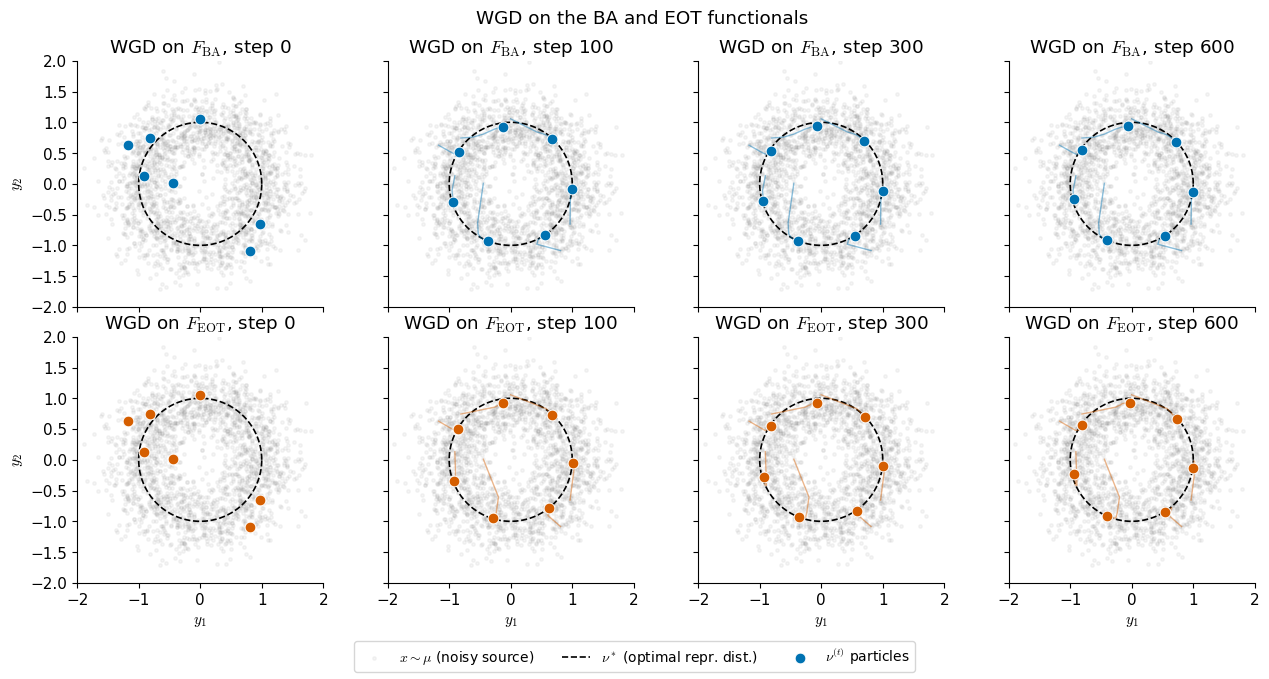

In [5]:
snapshot_ids = [np.argmin(abs(runs['BA']['steps'] - s)) for s in (0, 100, 300, num_steps)]
fig_snapshots, axs = plt.subplots(2, 4, figsize=(13, 6.8), sharex=True, sharey=True)
for row, method in enumerate(('BA', 'EOT')):
  r = runs[method]
  for col, k in enumerate(snapshot_ids):
    make_scatter(axs[row, col], r['nu_xs'][k], method_labels[method] + f', step {r["steps"][k]}', colors[method],
                 trajectories=r['nu_xs'][:k+1])
    if row == 0:
      axs[row, col].set_xlabel('')
    if col > 0:
      axs[row, col].set_ylabel('')
fig_snapshots.suptitle('WGD on the BA and EOT functionals')
handles, labels = axs[0, 0].get_legend_handles_labels()
fig_snapshots.legend(handles, labels, loc='lower center', ncol=3, fontsize=10)
fig_snapshots.tight_layout(rect=(0, 0.06, 1, 1))
display(fig_snapshots)
plt.close(fig_snapshots)


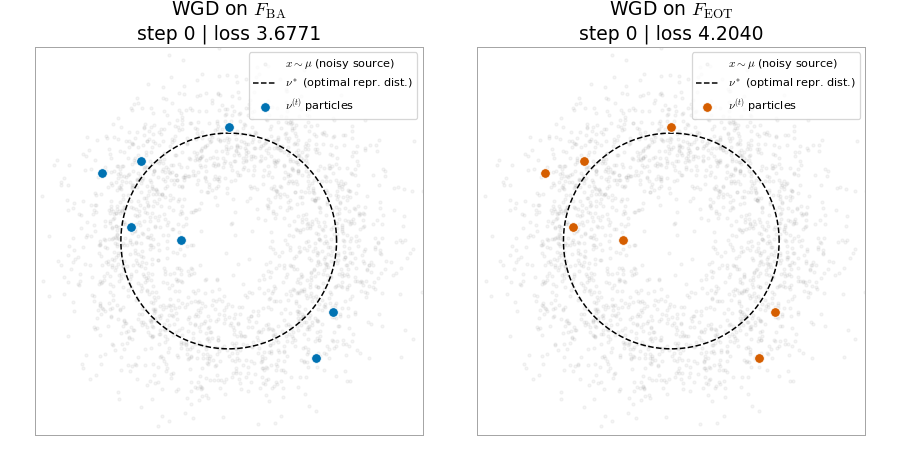

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5), dpi=90)
scatters, trails = {}, {}
for ax, method in zip(axs, ('BA', 'EOT')):
  make_scatter(ax, runs[method]['nu_xs'][0], method_labels[method], colors[method])
  scatters[method] = ax.collections[-1]
  trails[method] = [ax.plot([], [], color=colors[method], alpha=0.4, lw=1)[0] for _ in range(n)]
  ax.legend(fontsize=9, loc='upper right')
  ax.set(xlim=(-1.8, 1.8), ylim=(-1.8, 1.8), xlabel='', ylabel='', xticks=[], yticks=[])
  ax.minorticks_off()
  for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('0.65')
    spine.set_linewidth(0.8)

def animate(k):
  for ax, method in zip(axs, ('BA', 'EOT')):
    r = runs[method]
    scatters[method].set_offsets(r['nu_xs'][k])
    for j, line in enumerate(trails[method]):
      line.set_data(r['nu_xs'][:k+1, j, 0], r['nu_xs'][:k+1, j, 1])
    own_loss = r['ba_loss' if method == 'BA' else 'eot_loss'][k]
    ax.set_title(method_labels[method] + f'\nstep {r["steps"][k]} | loss {own_loss:.4f}', fontsize=15)
  return list(scatters.values())

animate(0)
fig.tight_layout()

frame_ids = np.arange(len(runs['BA']['steps']))
# Pause at the start and end.
frame_ids = np.r_[[frame_ids[0]] * 10, frame_ids, [frame_ids[-1]] * 10]
animation = FuncAnimation(fig, animate, frames=frame_ids, interval=100, blit=False)
gif_path = project_dir / 'results' / 'deconv' / f'nu_vs_t-method=ba_vs_eot-n={n}-lamb={rd_lambda:g}.gif'
gif_path.parent.mkdir(parents=True, exist_ok=True)
animation.save(gif_path, writer=PillowWriter(fps=10))
plt.close(fig)
gif_data = base64.b64encode(gif_path.read_bytes()).decode('ascii')
display(HTML(f'<img src="data:image/gif;base64,{gif_data}" width="900" alt="WGD on the BA and EOT functionals">'))

### Compare objectives

Evaluate both functionals along each trajectory. Let $q$ be the output marginal of the BA coupling;
we also plot $F_{\mathrm{EOT}}-F_{\mathrm{BA}}$ and $\|q-b\|_1$.

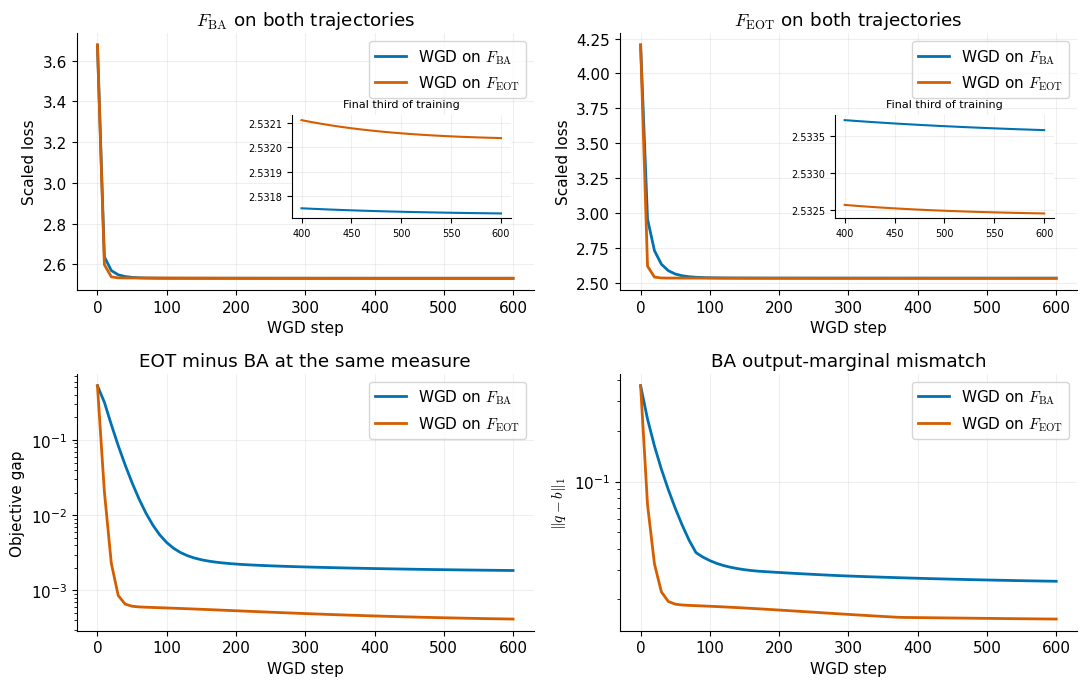

In [7]:
fig_losses, axs = plt.subplots(2, 2, figsize=(11, 7))
for method, r in runs.items():
  style = dict(color=colors[method], label=method_labels[method], lw=2)
  axs[0, 0].plot(r['steps'], r['ba_loss'], **style)
  axs[0, 1].plot(r['steps'], r['eot_loss'], **style)
  axs[1, 0].semilogy(r['steps'], np.maximum(r['eot_loss'] - r['ba_loss'], 1e-14), **style)
  axs[1, 1].semilogy(r['steps'], np.maximum(r['ba_marginal_error'], 1e-14), **style)
for ax, title, ylabel in zip(axs.flat,
    (r'$F_{\mathrm{BA}}$ on both trajectories', r'$F_{\mathrm{EOT}}$ on both trajectories',
     'EOT minus BA at the same measure', 'BA output-marginal mismatch'),
    ('Scaled loss', 'Scaled loss', 'Objective gap', r'$\|q-b\|_1$')):
  ax.set(title=title, xlabel='WGD step', ylabel=ylabel)
  ax.grid(alpha=0.2)
  ax.legend()
for ax, key in zip(axs[0], ('ba_loss', 'eot_loss')):
  inset = ax.inset_axes([0.47, 0.28, 0.48, 0.4])
  for method, r in runs.items():
    tail = r['steps'] >= 2 * num_steps / 3
    inset.plot(r['steps'][tail], r[key][tail], color=colors[method], lw=1.5)
  inset.set_title('Final third of training', fontsize=8)
  inset.tick_params(labelsize=7)
  inset.ticklabel_format(axis='y', style='plain', useOffset=False)
  inset.grid(alpha=0.2)
fig_losses.tight_layout()
display(fig_losses)
plt.close(fig_losses)

In [8]:
# Exact W2 between these two equal-weight discrete measures: optimal assignment.
ba_final, eot_final = runs['BA']['nu_xs'][-1], runs['EOT']['nu_xs'][-1]
cost = np.sum((ba_final[:, None, :] - eot_final[None, :, :])**2, axis=-1)
rows, cols = linear_sum_assignment(cost)
final_w2 = np.sqrt(cost[rows, cols].mean())

table = [
  r'| Final measure | $F_{\mathrm{BA}}$ | $F_{\mathrm{EOT}}$ | Mean BA gradient norm | Mean EOT gradient norm | BA marginal L1 error | Update seconds |',
  '|:---|---:|---:|---:|---:|---:|---:|',
]
for method, r in runs.items():
  table.append(f'| {method_labels[method]} | {r["ba_loss"][-1]:.8f} | {r["eot_loss"][-1]:.8f} | '
               f'{r["ba_grad_norm"][-1]:.3g} | {r["eot_grad_norm"][-1]:.3g} | '
               f'{r["ba_marginal_error"][-1]:.3g} | {r["update_seconds"][-1]:.3f} |')
display(Markdown('\n'.join(table)))
print(f'W2 distance between final equal-weight measures: {final_w2:.6g}')
print('Largest EOT training iteration count:', runs['EOT']['max_train_its'])

| Final measure | $F_{\mathrm{BA}}$ | $F_{\mathrm{EOT}}$ | Mean BA gradient norm | Mean EOT gradient norm | BA marginal L1 error | Update seconds |
|:---|---:|---:|---:|---:|---:|---:|
| WGD on $F_{\mathrm{BA}}$ | 2.53172883 | 2.53357251 | 0.00151 | 0.13 | 0.0256 | 0.071 |
| WGD on $F_{\mathrm{EOT}}$ | 2.53203664 | 2.53245365 | 0.0474 | 0.00344 | 0.0152 | 9.989 |

W2 distance between final equal-weight measures: 0.0200675
Largest EOT training iteration count: 194


### Symmetric two-point example

Take $\mu=\tfrac12(\delta_{-s}+\delta_s)$ and $\nu_r=\tfrac12(\delta_{-r}+\delta_r)$,
where $s$ and $r$ are the source and reproduction particle radii. Both measures have weights $(1/2,1/2)$.
By symmetry, the BA coupling has the prescribed output marginal, so both objectives equal

$$
F(r)=\frac{\lambda}{2}(s^2+r^2)-\log\cosh(\lambda sr).
$$

For $\lambda s^2>1$, the positive minimizer solves $r_*=s\tanh(\lambda s r_*)$;
otherwise $r_*=0$. Below we use $s=1$, $\lambda=2$ and initialize the particles at $\pm0.15$.

In [9]:
source_radius, lambda_sym = 1., 2.
mu_sym = jnp.array([[-source_radius], [source_radius]])
w_sym = jnp.array([[0.5, 0.5]])
init_sym = jnp.array([[-0.15], [0.15]])
radius_star = brentq(lambda r: r - source_radius*np.tanh(lambda_sym*source_radius*r), 1e-6, source_radius)

sym_runs = {}
for method in ('BA', 'EOT'):
  sym_runs[method] = run_wgd(mu_sym, w_sym.T, init_sym, w_sym, lambda_sym, method,
                            num_steps=150, learning_rate=0.1, record_every=1, tol=1e-12)

r_grid = np.linspace(0, 1.3, 101)
@jax.jit
def symmetric_losses(r):
  points = jnp.array([[-r], [r]])
  ba, _ = estimate_rd(mu_sym, w_sym.T, points, w_sym, 'half_sse', lambda_sym)
  eot, _ = estimate_eot(mu_sym, w_sym.T, points, w_sym, 'half_sse', lambda_sym, tol=1e-12)
  return ba['loss'], eot['loss'], eot['sinkhorn_converged']

ba_curve, eot_curve, converged = jax.vmap(symmetric_losses)(jnp.asarray(r_grid))
closed_form = lambda_sym / 2 * (source_radius**2 + r_grid**2) - (
    np.logaddexp(lambda_sym*source_radius*r_grid, -lambda_sym*source_radius*r_grid) - np.log(2))
assert np.all(converged)
np.testing.assert_allclose(ba_curve, closed_form, atol=1e-11, rtol=0)
np.testing.assert_allclose(eot_curve, closed_form, atol=1e-11, rtol=0)
np.testing.assert_allclose(sym_runs['BA']['nu_xs'], sym_runs['EOT']['nu_xs'], atol=1e-10, rtol=0)
for r in sym_runs.values():
  np.testing.assert_allclose(r['nu_xs'][-1, :, 0], [-radius_star, radius_star], atol=1e-8, rtol=0)
  assert np.max(r['ba_marginal_error']) < 1e-11

print(f'Analytic scalar root: r* = {radius_star:.10f}')
for method, r in sym_runs.items():
  print(f'{method}: final r={r["nu_xs"][-1, 1, 0]:.10f}, '
        f'F_BA={r["ba_loss"][-1]:.10f}, F_EOT={r["eot_loss"][-1]:.10f}')
print('Maximum trajectory discrepancy:', np.max(abs(sym_runs['BA']['nu_xs'] - sym_runs['EOT']['nu_xs'])))

Analytic scalar root: r* = 0.9575040241
BA: final r=0.9575040241, F_BA=0.6734761126, F_EOT=0.6734761126
EOT: final r=0.9575040241, F_BA=0.6734761126, F_EOT=0.6734761126
Maximum trajectory discrepancy: 2.220446049250313e-16


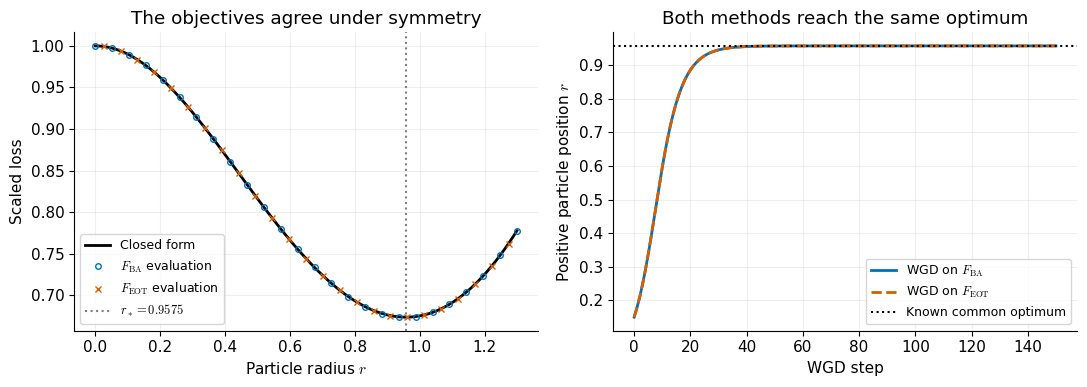

In [10]:
fig_symmetric, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(r_grid, closed_form, color='black', lw=2, label='Closed form')
axs[0].plot(r_grid[::4], np.asarray(ba_curve)[::4], 'o', ms=4, fillstyle='none',
            color=colors['BA'], label=r'$F_{\mathrm{BA}}$ evaluation')
axs[0].plot(r_grid[2::4], np.asarray(eot_curve)[2::4], 'x', ms=5,
            color=colors['EOT'], label=r'$F_{\mathrm{EOT}}$ evaluation')
axs[0].axvline(radius_star, ls=':', color='gray', label=rf'$r_* = {radius_star:.4f}$')
axs[0].set(xlabel='Particle radius $r$', ylabel='Scaled loss', title='The objectives agree under symmetry')
for method, r in sym_runs.items():
  axs[1].plot(r['steps'], r['nu_xs'][:, 1, 0], color=colors[method],
              ls='-' if method == 'BA' else '--', lw=2, label=method_labels[method])
axs[1].axhline(radius_star, color='black', ls=':', label='Known common optimum')
axs[1].set(xlabel='WGD step', ylabel='Positive particle position $r$', title='Both methods reach the same optimum')
for ax in axs:
  ax.grid(alpha=0.2)
  ax.legend(fontsize=9)
fig_symmetric.tight_layout()
display(fig_symmetric)
plt.close(fig_symmetric)

### Save figures and trajectories

In [11]:
save_artifacts = False
if save_artifacts:
  output_dir = project_dir / 'results' / 'eot_demo'
  output_dir.mkdir(parents=True, exist_ok=True)
  fig_snapshots.savefig(output_dir / 'particle_snapshots.png', bbox_inches='tight')
  fig_losses.savefig(output_dir / 'objective_comparison.png', bbox_inches='tight')
  fig_symmetric.savefig(output_dir / 'shared_optimum.png', bbox_inches='tight')
  arrays = {f'{method.lower()}_{key}': value for method, r in runs.items() for key, value in r.items()}
  np.savez(output_dir / 'trajectories.npz', mu_x=mu_x, mu_w=mu_w, nu_w=nu_w,
           rd_lambda=rd_lambda, learning_rate=learning_rate, seed=seed, **arrays)
  print('Saved figures and trajectories to', output_dir)